In [3]:
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping, ModelCheckpoint
from tensorflow.keras.preprocessing.image import load_img, img_to_array, ImageDataGenerator
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
model = models.Sequential([
    layers.InputLayer(input_shape=(256, 256, 3)),
    
    # First Convolutional Block
    layers.Conv2D(32, (3, 3), padding='same', kernel_regularizer=tf.keras.regularizers.l2(0.0001)),
    layers.LeakyReLU(alpha=0.01),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),

    # Second Convolutional Block
    layers.Conv2D(64, (3, 3), padding='same', kernel_regularizer=tf.keras.regularizers.l2(0.00015)),
    layers.LeakyReLU(alpha=0.01),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),

    # Third Convolutional Block
    layers.Conv2D(128, (3, 3), padding='same', kernel_regularizer=tf.keras.regularizers.l2(0.0002)),
    layers.LeakyReLU(alpha=0.01),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),

    # Fourth Convolutional Block
    layers.Conv2D(256, (3, 3), padding='same', kernel_regularizer=tf.keras.regularizers.l2(0.00025)),
    layers.LeakyReLU(alpha=0.01),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),

    # Fifth Convolutional Block
    layers.Conv2D(512, (3, 3), padding='same', kernel_regularizer=tf.keras.regularizers.l2(0.0003)),
    layers.LeakyReLU(alpha=0.01),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),
    
    # Sixth Convolutional Block
    layers.Conv2D(1024, (3, 3), padding='same', kernel_regularizer=tf.keras.regularizers.l2(0.00035)),
    layers.LeakyReLU(alpha=0.01),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),
    layers.Dropout(0.3),
    
    # Fully Connected Layers
    layers.GlobalAveragePooling2D(),
    layers.Dense(512, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.0004)),
    layers.Dropout(0.4),
    
    # Output Layer for 3 Classes
    layers.Dense(3, activation='softmax')
])

In [6]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 256, 256, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 256, 256, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 256, 256, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 128, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 32, 32, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_9 (LeakyReLU)       │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 32, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 16, 16, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_10 (LeakyReLU)      │ (None, 16, 16, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 16, 16, 512)    │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 8, 8, 1024)     │     4,719,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_11 (LeakyReLU)      │ (None, 8, 8, 1024)     │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 6,822,595 (26.03 MB)

 Trainable params: 6,818,563 (26.01 MB)

 Non-trainable params: 4,032 (15.75 KB)

In [ ]:
train_dir = '/kaggle/input/merged-augmented/Train'
validation_dir = '/kaggle/input/merged-augmented/Valid'
test_dir = '/kaggle/input/merged-augmented/Test'

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

validation_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(256, 256),
    batch_size=32,
    class_mode='categorical',
    shuffle=True,
    seed=42
)

validation_generator = validation_datagen.flow_from_directory(
    validation_dir,
    target_size=(256, 256),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(256, 256),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 8693 images belonging to 3 classes.
Found 1738 images belonging to 3 classes.
Found 1162 images belonging to 3 classes.


In [ ]:
optimizer = Adam(learning_rate=0.0001, clipnorm=1.0)
model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

# Adjusting the Callbacks
lr_callback = ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=3, min_lr=1e-6)
early_stopping = EarlyStopping(monitor='val_loss', patience=10, min_delta=0.001, restore_best_weights=True)
model_checkpoint = ModelCheckpoint(monitor='val_acc', filepath='best_model.keras', save_best_only=True)

# Train the Model
history = model.fit(
    train_generator,
    epochs=100,
    validation_data=validation_generator,
    callbacks=[lr_callback, early_stopping, model_checkpoint],
    verbose=1
)

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/100


I0000 00:00:1756139314.947548      76 service.cc:148] XLA service 0x7e6414001cc0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1756139314.953082      76 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1756139314.953109      76 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1756139316.314015      76 cuda_dnn.cc:529] Loaded cuDNN version 90300


  1/272 ━━━━━━━━━━━━━━━━━━━━ 1:53:48 25s/step - accuracy: 0.3750 - loss: 2.1309

I0000 00:00:1756139332.107978      76 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


272/272 ━━━━━━━━━━━━━━━━━━━━ 147s 448ms/step - accuracy: 0.6676 - loss: 1.5798 - val_accuracy: 0.3159 - val_loss: 5.4502 - learning_rate: 1.0000e-04
Epoch 2/100


/usr/local/lib/python3.11/dist-packages/keras/src/callbacks/model_checkpoint.py:209: UserWarning: Can save best model only with val_acc available, skipping.
  self._save_model(epoch=epoch, batch=None, logs=logs)


272/272 ━━━━━━━━━━━━━━━━━━━━ 32s 116ms/step - accuracy: 0.8452 - loss: 1.0882 - val_accuracy: 0.7474 - val_loss: 1.2647 - learning_rate: 1.0000e-04
Epoch 3/100
272/272 ━━━━━━━━━━━━━━━━━━━━ 31s 114ms/step - accuracy: 0.8962 - loss: 0.9520 - val_accuracy: 0.9229 - val_loss: 0.8780 - learning_rate: 1.0000e-04
Epoch 4/100
272/272 ━━━━━━━━━━━━━━━━━━━━ 31s 114ms/step - accuracy: 0.9178 - loss: 0.8629 - val_accuracy: 0.9287 - val_loss: 0.8300 - learning_rate: 1.0000e-04
Epoch 5/100
272/272 ━━━━━━━━━━━━━━━━━━━━ 31s 115ms/step - accuracy: 0.9414 - loss: 0.7727 - val_accuracy: 0.9574 - val_loss: 0.7095 - learning_rate: 1.0000e-04
Epoch 6/100
272/272 ━━━━━━━━━━━━━━━━━━━━ 31s 114ms/step - accuracy: 0.9574 - loss: 0.7059 - val_accuracy: 0.9591 - val_loss: 0.6972 - learning_rate: 1.0000e-04
Epoch 7/100
272/272 ━━━━━━━━━━━━━━━━━━━━ 31s 115ms/step - accuracy: 0.9658 - loss: 0.6534 - val_accuracy: 0.9603 - val_loss: 0.6568 - learning_rate: 1.0000e-04
Epoch 8/100
272/272 ━━━━━━━━━━━━━━━━━━━━ 31s 114ms/s

# **Performance Matrics and Confusion Matrix**

36/36 ━━━━━━━━━━━━━━━━━━━━ 12s 345ms/step - accuracy: 0.9849 - loss: 0.1272
Test Accuracy: 0.98


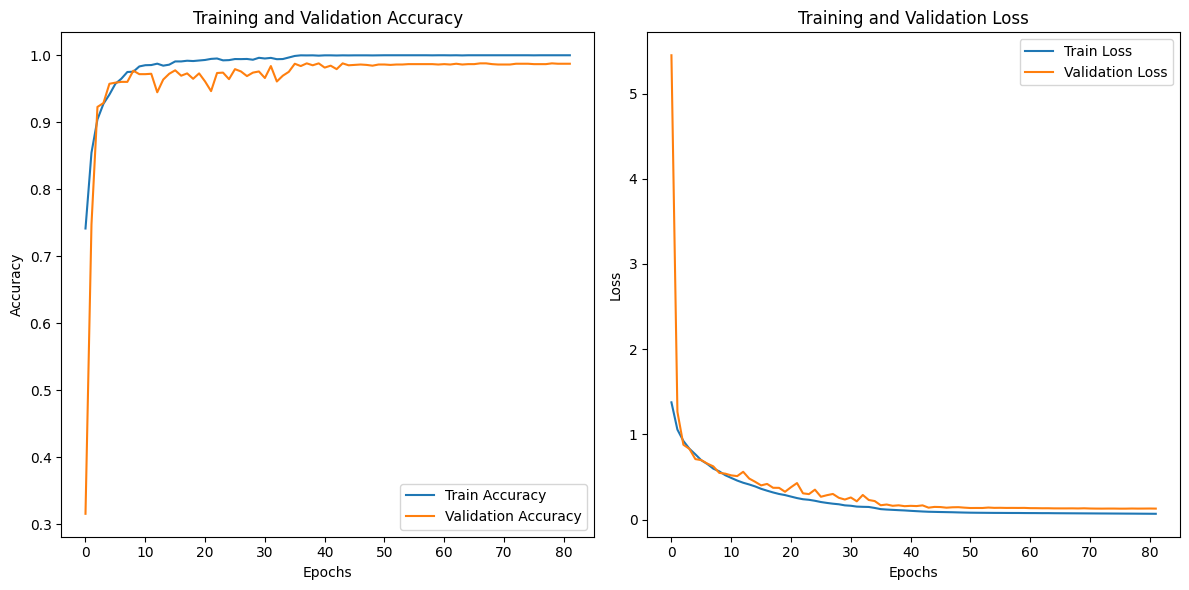

In [9]:
# Evaluating the model on test data
test_loss, test_accuracy = model.evaluate(test_generator, steps=test_generator.samples // test_generator.batch_size)
print(f"Test Accuracy: {test_accuracy:.2f}")

# Plot Training & Validation Accuracy and Loss, along with Test Accuracy
epochs = range(len(history.history['accuracy']))

plt.figure(figsize=(12, 6))

# Plot Training and Validation Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs, history.history['accuracy'], label='Train Accuracy')
plt.plot(epochs, history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
# plt.ylim(0.3, 1)
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

# Plot Training and Validation Loss
plt.subplot(1, 2, 2)
plt.plot(epochs, history.history['loss'], label='Train Loss')
plt.plot(epochs, history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')

plt.tight_layout()
plt.show()

37/37 ━━━━━━━━━━━━━━━━━━━━ 5s 100ms/step

Total Predicted Items: 1162

Total Correct Predictions: 1142
Total Incorrect Predictions: 20
Accuracy on Test Set (manual): 98.28%
37/37 ━━━━━━━━━━━━━━━━━━━━ 3s 75ms/step


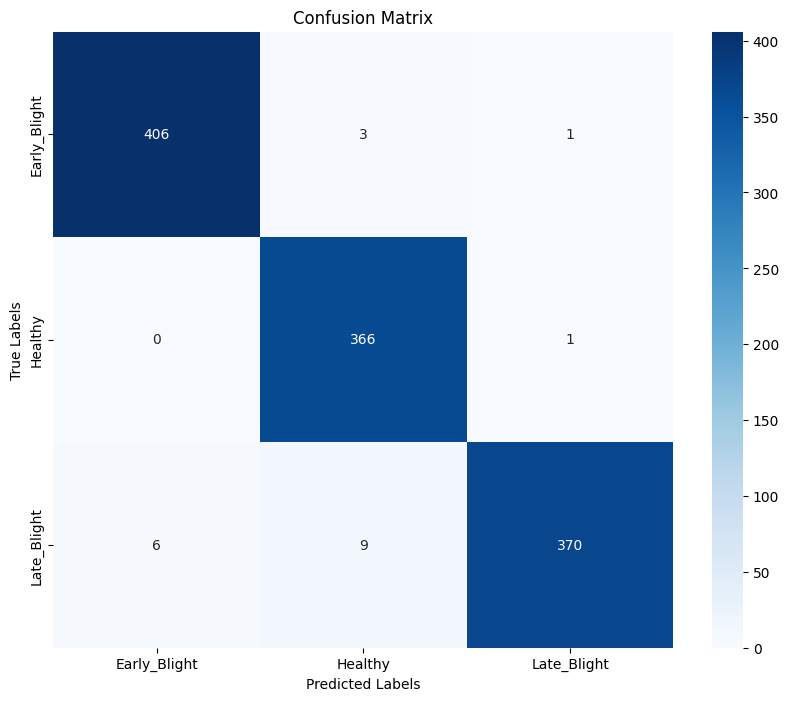

Classification Report:
              precision    recall  f1-score   support

Early_Blight       0.99      0.99      0.99       410
     Healthy       0.97      1.00      0.98       367
 Late_Blight       0.99      0.96      0.98       385

    accuracy                           0.98      1162
   macro avg       0.98      0.98      0.98      1162
weighted avg       0.98      0.98      0.98      1162



In [10]:
# Get predictions
predictions = model.predict(test_generator, verbose=1)

# Convert predictions to class indices
predicted_classes = np.argmax(predictions, axis=1)
true_classes = test_generator.classes
class_labels = list(test_generator.class_indices.keys())

# Calculate correct and incorrect counts
correct_count = np.sum(predicted_classes == true_classes)
incorrect_count = len(true_classes) - correct_count

# Print results
print(f"\nTotal Predicted Items: {correct_count + incorrect_count}")
print(f"\nTotal Correct Predictions: {correct_count}")
print(f"Total Incorrect Predictions: {incorrect_count}")
print(f"Accuracy on Test Set (manual): {correct_count / len(true_classes) * 100:.2f}%")

# Get predictions and true labels
predictions = model.predict(test_generator, verbose=1)
predicted_classes = np.argmax(predictions, axis=1)
true_classes = test_generator.classes
class_labels = list(test_generator.class_indices.keys())

# Confusion Matrix
conf_matrix = confusion_matrix(true_classes, predicted_classes)
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

# Classification Report
print("Classification Report:")
print(classification_report(true_classes, predicted_classes, target_names=class_labels))

# **GradCAM Implementation**

In [11]:
import os, cv2
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

In [12]:
# 1) List conv layer names
def list_conv_layers(keras_model):
    return [l.name for l in keras_model.layers if isinstance(l, tf.keras.layers.Conv2D)]

In [13]:
# 2) Load and preprocess image
def load_image_rgb(path, size=(256, 256)):
    bgr = cv2.imread(path)
    if bgr is None:
        raise FileNotFoundError(f"Could not read image: {path}")
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    rgb = cv2.resize(rgb, size, interpolation=cv2.INTER_AREA)
    return rgb

In [14]:
# 3) GradCAM Computation
def compute_gradcam(model, img_rgb_uint8, layer_name, class_index=None):
    img = img_rgb_uint8.astype(np.float32) / 255.0
    x = np.expand_dims(img, axis=0)

    # Forward pass to get actual graph tensors
    outputs_dict = {}
    def get_output(layer):
        outputs_dict[layer.name] = layer.output

    # Collect all Conv2D layers
    for layer in model.layers:
        if isinstance(layer, tf.keras.layers.Conv2D) or hasattr(layer, 'layers'):
            try:
                get_output(layer)
            except:
                pass

    # Warm-up call to build the model
    preds = model(x)

    # Get the target conv layer output (already connected in the graph)
    target_layer = None
    for layer in model.layers:
        if layer.name == layer_name:
            target_layer = layer
        elif hasattr(layer, 'layers'):
            for sub in layer.layers:
                if sub.name == layer_name:
                    target_layer = sub
    if target_layer is None:
        raise ValueError(f"Layer {layer_name} not found")

    conv_output = target_layer.output

    # Create grad model from actual Input tensor
    grad_model = tf.keras.models.Model(inputs=model.inputs[0],
                                       outputs=[conv_output, model.outputs[0]])

    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(x)
        if class_index is None:
            class_index = tf.argmax(preds[0])
        loss = preds[:, class_index]

    grads = tape.gradient(loss, conv_out)
    weights = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.reduce_sum(conv_out * tf.reshape(weights, [1, 1, 1, -1]), axis=-1)
    cam = tf.squeeze(cam)
    cam = tf.maximum(cam, 0)
    cam /= (tf.reduce_max(cam) + 1e-8)
    cam = cam.numpy()

    cam_resized = cv2.resize(cam, (img_rgb_uint8.shape[1], img_rgb_uint8.shape[0]),
                              interpolation=cv2.INTER_CUBIC)
    return cam_resized, int(class_index), float(tf.reduce_max(preds[0]).numpy())

In [15]:
# 4) Overlay heatmap
def overlay_heatmap(img_rgb_uint8, heatmap01, alpha=0.5, cmap_name='jet'):
    cmap = plt.get_cmap(cmap_name)
    heatmap_rgba = cmap(heatmap01)
    heatmap_rgb = (heatmap_rgba[..., :3] * 255).astype(np.uint8)
    blended = (alpha * heatmap_rgb + (1 - alpha) * img_rgb_uint8).clip(0, 255).astype(np.uint8)
    return blended, heatmap_rgba

In [16]:
from matplotlib.cm import ScalarMappable
import matplotlib as mpl
from matplotlib.gridspec import GridSpec
import matplotlib.pyplot as plt

In [17]:
# 5) Plot panel
def plot_gradcam_panel(image_paths, model, layer_name, class_indices=None, alpha=0.5,
                       class_names=None, save_path="figure_gradcam_panel.png"):
    imgs_rgb = [load_image_rgb(p) for p in image_paths]
    cams, preds_idx, preds_conf = [], [], []

    for i, img in enumerate(imgs_rgb):
        idx = None if (class_indices is None) else class_indices[i]
        cam, chosen_idx, confidence = compute_gradcam(model, img, layer_name, class_index=idx)
        cams.append(cam)
        preds_idx.append(chosen_idx)
        preds_conf.append(confidence)

    n = len(image_paths)
    fig = plt.figure(figsize=(12, 4 * n))
    gs = GridSpec(n, 3, width_ratios=[1, 1, 0.05], figure=fig, wspace=0.15, hspace=0.25)

    for i in range(n):
        img = imgs_rgb[i]
        cam = cams[i]

        # Original image
        ax0 = fig.add_subplot(gs[i, 0])
        ax0.imshow(img)
        ax0.axis("off")
        title_left = "Original"
        if class_names:
            title_left += f" — {class_names[preds_idx[i]]} ({preds_conf[i]:.2f})"
        ax0.set_title(title_left)

        # Grad-CAM overlay
        blended, _ = overlay_heatmap(img, cam, alpha=alpha)
        ax1 = fig.add_subplot(gs[i, 1])
        ax1.imshow(blended)
        ax1.axis("off")
        ax1.set_title("Grad-CAM Overlay")

    # Always make colorbar from a dummy ScalarMappable (not from alpha=0 images)
    norm = mpl.colors.Normalize(vmin=0.0, vmax=1.0)
    sm = ScalarMappable(norm=norm, cmap='jet')
    sm.set_array([])

    cax = fig.add_subplot(gs[:, 2])
    cbar = fig.colorbar(sm, cax=cax, ticks=[0, 0.25, 0.5, 0.75, 1.0])
    cbar.set_label("Grad-CAM Intensity")

    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

['conv2d_6', 'conv2d_7', 'conv2d_8', 'conv2d_9', 'conv2d_10', 'conv2d_11']


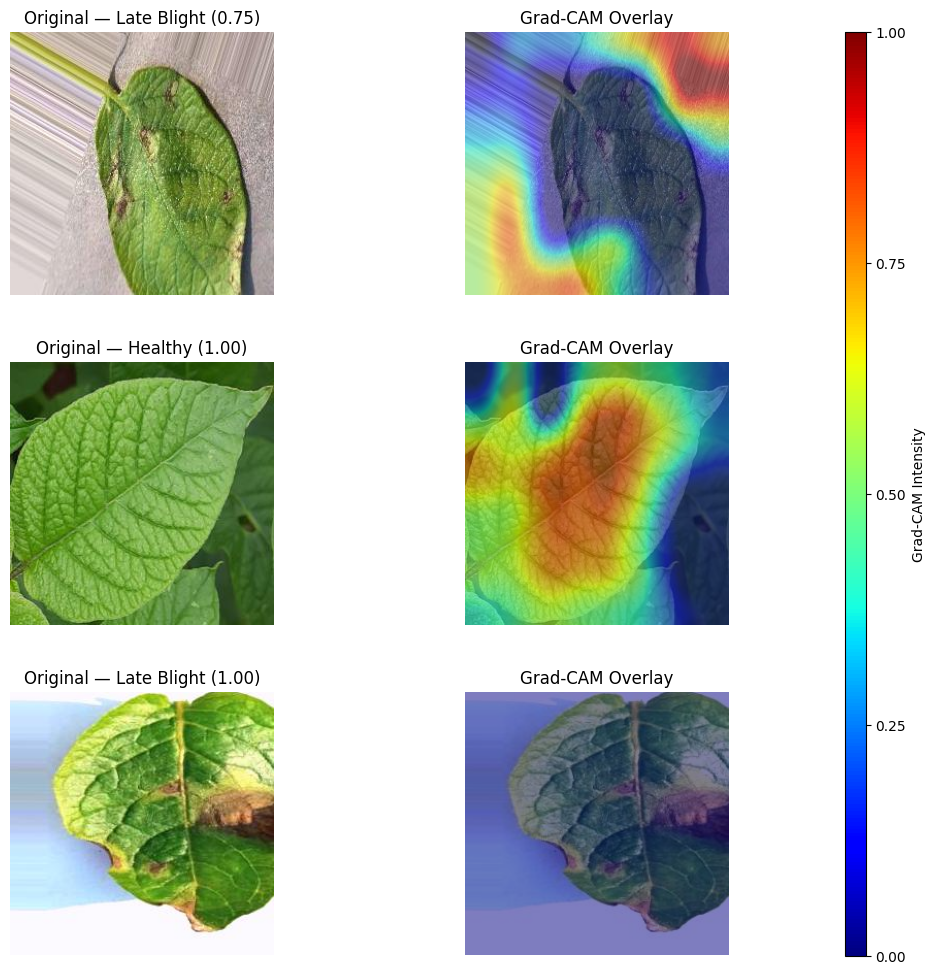

In [18]:
# -------------------
# First Intensity Bar:
# -------------------
print(list_conv_layers(model))
layer_name = "conv2d_11" #update accordingly

image_paths = [
    "/kaggle/input/test-set/image_1.png",
    "/kaggle/input/test-set/image_2.png",
    "/kaggle/input/test-set/image_5.png",
]

class_names = ["Early Blight", "Healthy", "Late Blight"]

_ = model(np.zeros((1, 256, 256, 3), dtype=np.float32))
plot_gradcam_panel(image_paths, model, layer_name, class_names=class_names)

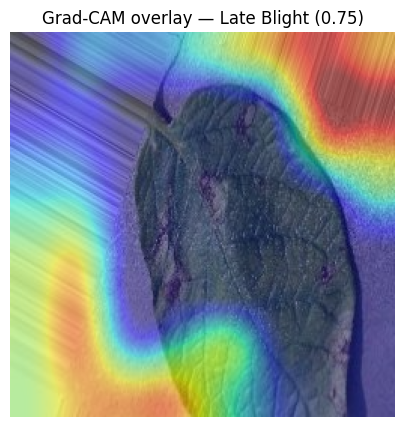

Saved: /kaggle/working/figure_gradcam_1.png


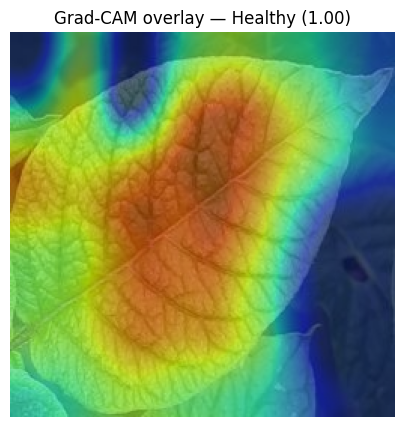

Saved: /kaggle/working/figure_gradcam_2.png


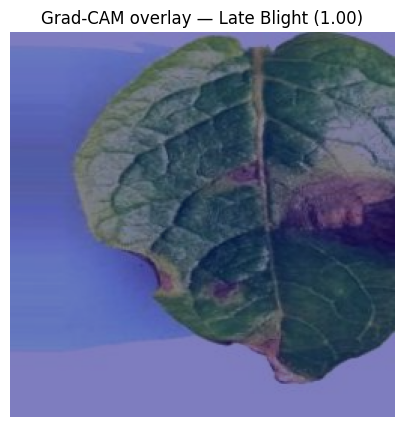

Saved: /kaggle/working/figure_gradcam_3.png


In [19]:
class_indices = None

for i, p in enumerate(image_paths):
    img = load_image_rgb(p)
    cam, idx, conf = compute_gradcam(
        model,
        img,
        layer_name,
        class_index=None if class_indices is None else class_indices[i]
    )
    blended, _ = overlay_heatmap(img, cam, alpha=0.5)
    out_path = f"figure_gradcam_{i+1}.png"
    plt.figure(figsize=(5, 5))
    plt.imshow(blended)
    plt.axis('off')
    title = f"Grad-CAM overlay — {class_names[idx] if class_names else f'class {idx}'} ({conf:.2f})"
    plt.title(title, fontsize=12)
    plt.savefig(out_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Saved: {os.path.abspath(out_path)}")

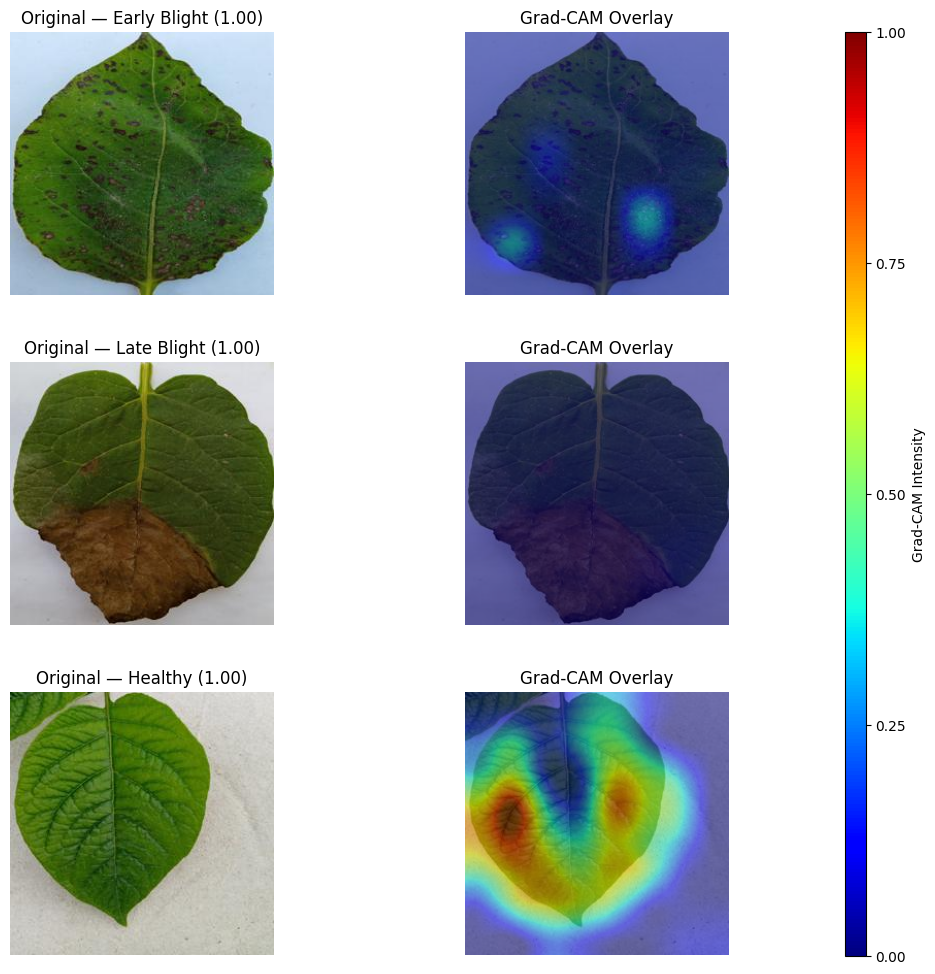

In [22]:
# -------------------
# Second Intensity Bar:
# -------------------

image_paths = [
    "/kaggle/input/merged-augmented/Train/Early_Blight/Early_Blight_322.jpg",
    "/kaggle/input/merged-augmented/Train/Late_Blight/Late_Blight_792.jpg",
    "/kaggle/input/merged-augmented/Train/Healthy/Healthy_273.jpg",
]

class_names = ["Early Blight", "Healthy", "Late Blight"]

_ = model(np.zeros((1, 256, 256, 3), dtype=np.float32))
plot_gradcam_panel(image_paths, model, layer_name, class_names=class_names)

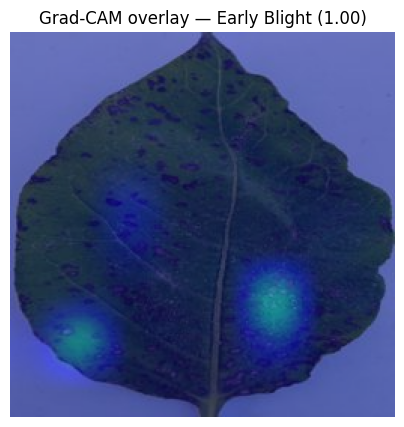

Saved: /kaggle/working/figure_gradcam_1.png


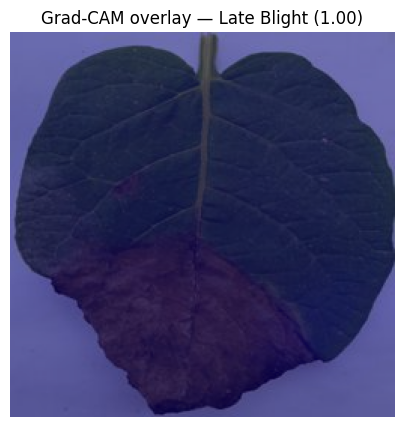

Saved: /kaggle/working/figure_gradcam_2.png


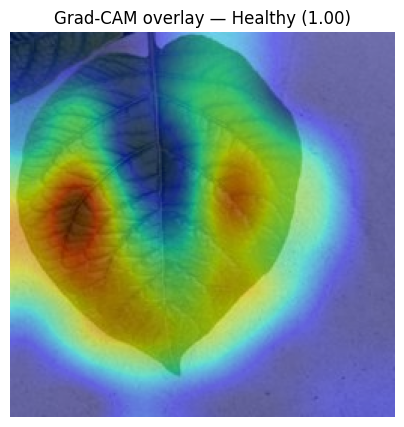

Saved: /kaggle/working/figure_gradcam_3.png


In [23]:
class_indices = None

for i, p in enumerate(image_paths):
    img = load_image_rgb(p)
    cam, idx, conf = compute_gradcam(
        model,
        img,
        layer_name,
        class_index=None if class_indices is None else class_indices[i]
    )
    blended, _ = overlay_heatmap(img, cam, alpha=0.5)
    out_path = f"figure_gradcam_{i+1}.png"
    plt.figure(figsize=(5, 5))
    plt.imshow(blended)
    plt.axis('off')
    title = f"Grad-CAM overlay — {class_names[idx] if class_names else f'class {idx}'} ({conf:.2f})"
    plt.title(title, fontsize=12)
    plt.savefig(out_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Saved: {os.path.abspath(out_path)}")